# Q11 SuperTrend 与低波趋势 LVT 的交叉验证

目标：在 Q8 theme-alpha 近实盘基准上，判断 SuperTrend 与 LowVolTrend 是否互补，还是重复过滤。

本 notebook 保持 Q8 口径：

- 核心：Core80 / Expanded LVT20 / Def200 Cash
- 调仓：fixed twice-monthly，月内 10 日和 25 日，顺延到下一个可交易日
- 执行：close signal，next close trade
- 成本：20 bps base cost + asset-specific friction
- 控制：2% minimum rebalance threshold，15% max single-ETF trade per rebalance

默认 SuperTrend 参数沿用 Q9/Q10 的均衡版本：ATR 10 / multiplier 3，并额外测试 ATR 7/10/14 与 multiplier 2/3/4。


In [1]:
from pathlib import Path
import warnings
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "SimHei", "STHeiti"]
plt.rcParams["axes.unicode_minus"] = False

OUTPUT_DIR = Path("outputs/q11-supertrend-lvt-cross-validation")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_START = "2020-01-01"
END = (pd.Timestamp.today() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
TRADING_DAYS = 252
INITIAL_NAV = 100.0
REBALANCE_ANCHOR = "2020-01-02"

CSI300 = "510300.SS"
NASDAQ = "513100.SS"
NONFERROUS = "512400.SS"
CHIP = "159995.SZ"
COMM = "515880.SS"
GOLD = "518880.SS"
DIVIDEND = "510880.SS"
ENERGY = "159930.SZ"
BROKER = "512880.SS"
HK_TECH = "513180.SS"
HEALTHCARE = "512170.SS"

CORE_ASSETS = (CSI300, NASDAQ, GOLD)
EXPANDED_THEME = (NASDAQ, NONFERROUS, CHIP, COMM, GOLD, DIVIDEND, ENERGY, BROKER, HK_TECH, HEALTHCARE)
ALL_SYMBOLS = tuple(dict.fromkeys(CORE_ASSETS + EXPANDED_THEME))
SYMBOL_NAMES = {
    CSI300: "沪深300ETF",
    NASDAQ: "纳指100ETF",
    NONFERROUS: "有色金属ETF",
    CHIP: "芯片ETF",
    COMM: "通信ETF",
    GOLD: "黄金ETF",
    DIVIDEND: "红利ETF",
    ENERGY: "能源ETF",
    BROKER: "证券ETF",
    HK_TECH: "恒生科技ETF",
    HEALTHCARE: "医疗ETF",
}

MA_WINDOW = 60
MOM_WINDOW = 63
VOL_WINDOW = 60
TOP_N = 3
RP_VOL_WINDOW = 20
CAP = 0.50
DEFENSE_WINDOW = 200
BASE_COST_BPS = 20
THRESHOLD = 0.02
MAX_TRADE = 0.15
DEFAULT_ATR = 10
DEFAULT_MULTIPLIER = 3.0
PARAM_GRID = [(atr, mult) for atr in [7, 10, 14] for mult in [2.0, 3.0, 4.0]]

SCHEDULE = "BIMONTHLY"
EXECUTION_MODE = "next_close"
FRICTION_MODE = "base20_plus_asset"

WINDOWS = {
    "full_sample": (None, None),
    "2021_to_date": ("2021-01-01", None),
    "2022_bear": ("2022-01-01", "2022-12-31"),
    "2025_to_date": ("2025-01-01", None),
    "2026_ytd": ("2026-01-01", None),
}

ASSET_EXTRA_FRICTION_BPS = {
    CSI300: 5,
    GOLD: 5,
    DIVIDEND: 5,
    NASDAQ: 20,
    HK_TECH: 20,
    NONFERROUS: 10,
    CHIP: 10,
    COMM: 10,
    ENERGY: 10,
    BROKER: 10,
    HEALTHCARE: 10,
}

STRATEGY_DEFINITIONS = {
    "Q8_Baseline": "Q8 default: Core80 / Expanded LVT20 / Def200 Cash. This is identical to Pure_LVT_Satellite by construction.",
    "Pure_LVT_Satellite": "Core80 / Def200 Cash plus 20% Expanded LVT satellite.",
    "Pure_ST_Satellite": "Core80 / Def200 Cash plus 20% Expanded SuperTrend satellite; same Expanded pool and same satellite budget; no ST asset means satellite cash.",
    "LVT_ST_EntryFilter": "LVT names can enter only when SuperTrend is long; existing LVT names may remain until LVT drops them.",
    "LVT_ST_ExitFilter": "LVT names are removed once an already-held name is SuperTrend short; new LVT names are not entry-gated.",
    "LVT_ST_Vote_HalfWeight": "LVT-selected and ST-long names keep normal LVT weights; LVT-selected but ST-short names are cut to half weight, with freed weight to cash.",
    "LVT_ST_Vote_FullExit": "LVT-selected but ST-short names are fully moved to cash without redistributing to other satellite names.",
    "LVT_ST_EntryExit": "Upper-reference filter: only names passing both LVT and SuperTrend receive satellite allocation, re-normalized to the satellite budget.",
}

print(f"Output dir: {OUTPUT_DIR}")
print(f"End date request: {END}")


Output dir: outputs/q11-supertrend-lvt-cross-validation
End date request: 2026-06-25


## 数据下载与 Q8 口径函数


In [2]:
def _flatten_yfinance_columns(df, symbol):
    out = df.copy()
    if isinstance(out.columns, pd.MultiIndex):
        out.columns = [col[0] if len(col) > 1 and col[1] == symbol else "_".join(map(str, col)).strip() for col in out.columns]
    out.columns = [str(c).lower().replace(" ", "_") for c in out.columns]
    return out


def download_symbol(symbol):
    df = yf.download(symbol, start=DATA_START, end=END, auto_adjust=True, progress=False, threads=False)
    if df.empty:
        raise RuntimeError(f"No data downloaded for {symbol}")
    df = _flatten_yfinance_columns(df, symbol)
    required = ["open", "high", "low", "close", "volume"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise RuntimeError(f"{symbol} missing columns: {missing}")
    df = df[required].dropna(subset=["close"]).copy()
    df.index = pd.DatetimeIndex(df.index).tz_localize(None).normalize()
    return df


raw = {sym: download_symbol(sym) for sym in ALL_SYMBOLS}
index = pd.DatetimeIndex(sorted(set().union(*[set(df.index) for df in raw.values()])))

open_raw = pd.DataFrame({sym: raw[sym]["open"].reindex(index) for sym in ALL_SYMBOLS})
high_raw = pd.DataFrame({sym: raw[sym]["high"].reindex(index) for sym in ALL_SYMBOLS})
low_raw = pd.DataFrame({sym: raw[sym]["low"].reindex(index) for sym in ALL_SYMBOLS})
close_raw = pd.DataFrame({sym: raw[sym]["close"].reindex(index) for sym in ALL_SYMBOLS})
volume_raw = pd.DataFrame({sym: raw[sym]["volume"].reindex(index) for sym in ALL_SYMBOLS})

open_ = open_raw.ffill()
high = high_raw.ffill()
low = low_raw.ffill()
close = close_raw.ffill()
volume = volume_raw.fillna(0.0)
value_traded = close_raw * volume_raw
adv20 = value_traded.fillna(0.0).rolling(20, min_periods=5).mean()
returns = close.pct_change(fill_method=None)

availability = pd.DataFrame([
    {
        "symbol": sym,
        "name": SYMBOL_NAMES[sym],
        "first_date": close_raw[sym].dropna().index.min().date(),
        "last_date": close_raw[sym].dropna().index.max().date(),
        "price_rows": int(close_raw[sym].dropna().shape[0]),
        "volume_rows": int(volume_raw[sym].dropna().shape[0]),
    }
    for sym in ALL_SYMBOLS
])
availability.to_csv(OUTPUT_DIR / "data_availability.csv", index=False, encoding="utf-8-sig")
display(availability)
print(f"Backtest calendar: {close.index[0].date()} to {close.index[-1].date()}, rows={len(close)}")


,symbol,name,first_date,last_date,price_rows,volume_rows
0,510300.SS,沪深300ETF,2020-01-02,2026-06-24,1566,1566
1,513100.SS,纳指100ETF,2020-01-02,2026-06-24,1567,1567
2,518880.SS,黄金ETF,2020-01-02,2026-06-24,1566,1566
3,512400.SS,有色金属ETF,2020-01-02,2026-06-24,1566,1566
4,159995.SZ,芯片ETF,2020-01-20,2026-06-24,1548,1548
5,515880.SS,通信ETF,2020-01-02,2026-06-24,1566,1566
6,510880.SS,红利ETF,2020-01-02,2026-06-24,1566,1566
7,159930.SZ,能源ETF,2020-01-02,2026-06-24,1544,1544
8,512880.SS,证券ETF,2020-01-02,2026-06-24,1566,1566
9,513180.SS,恒生科技ETF,2021-05-18,2026-06-24,1234,1234


Backtest calendar: 2020-01-02 to 2026-06-24, rows=1567


In [3]:
def normalize_weights(weights, universe):
    clean = {sym: float(max(0.0, weights.get(sym, 0.0))) for sym in universe}
    total = sum(clean.values())
    if total > 1.0 + 1e-12:
        clean = {sym: val / total for sym, val in clean.items()}
        total = 1.0
    clean["CASH"] = max(0.0, 1.0 - total)
    return clean


def apply_cap(weights, universe, cap=None):
    if cap is None:
        return normalize_weights(weights, universe)
    s = pd.Series({sym: max(0.0, weights.get(sym, 0.0)) for sym in universe}, dtype=float)
    total = s.sum()
    if total <= 0:
        return normalize_weights({}, universe)
    s = s / total
    cap = float(cap)
    for _ in range(30):
        over = s > cap + 1e-12
        if not over.any():
            break
        excess = (s[over] - cap).sum()
        s[over] = cap
        under = s < cap - 1e-12
        capacity = (cap - s[under]).clip(lower=0.0)
        if excess <= 1e-12 or capacity.sum() <= 1e-12:
            break
        base = s[under].clip(lower=0.0)
        add = excess * (base / base.sum() if base.sum() > 1e-12 else capacity / capacity.sum())
        add = np.minimum(add, capacity)
        s.loc[add.index] += add
    return normalize_weights(s.to_dict(), universe)


def signal_dates(index, schedule=SCHEDULE):
    idx = pd.DatetimeIndex(index)
    if schedule == "BIMONTHLY":
        dates = []
        months = pd.period_range(idx.min().to_period("M"), idx.max().to_period("M"), freq="M")
        for p in months:
            for day in (10, 25):
                anchor = pd.Timestamp(year=p.year, month=p.month, day=min(day, p.days_in_month))
                pos = idx.searchsorted(anchor)
                if pos < len(idx) and idx[pos].to_period("M") == p:
                    dates.append(idx[pos])
        return set(pd.DatetimeIndex(sorted(set(dates))))
    raise ValueError(schedule)


SDATES = signal_dates(close.index, SCHEDULE)


def enough_history(sym, loc, window):
    if loc < window:
        return False
    hist = close[sym].iloc[loc - window + 1:loc + 1]
    return hist.notna().all()


def enough_ohlc_history(sym, loc, window):
    if loc < window:
        return False
    return (
        high[sym].iloc[loc - window + 1:loc + 1].notna().all()
        and low[sym].iloc[loc - window + 1:loc + 1].notna().all()
        and close[sym].iloc[loc - window + 1:loc + 1].notna().all()
    )


def enough_return_history(sym, loc, window):
    if loc < window:
        return False
    hist = returns[sym].iloc[loc - window + 1:loc + 1]
    return hist.notna().all()


def risk_parity_weight(date, eligible, universe, cap=None):
    loc = close.index.get_loc(date)
    eligible = [sym for sym in eligible if sym in universe and enough_return_history(sym, loc, RP_VOL_WINDOW)]
    if not eligible:
        return normalize_weights({}, universe)
    hist = returns.iloc[loc - RP_VOL_WINDOW + 1:loc + 1][eligible]
    vols = hist.std(ddof=1).replace(0, np.nan).dropna()
    vols = vols[vols > 0]
    if vols.empty:
        return normalize_weights({}, universe)
    inv = 1.0 / vols
    raw = (inv / inv.sum()).to_dict()
    return apply_cap(raw, universe, cap)


def low_vol_trend_selection(date, universe=EXPANDED_THEME):
    loc = close.index.get_loc(date)
    warmup = max(MA_WINDOW, MOM_WINDOW, VOL_WINDOW)
    if loc < warmup:
        return []
    valid = []
    for sym in universe:
        if not enough_history(sym, loc, max(MA_WINDOW, MOM_WINDOW + 1)):
            continue
        if not enough_return_history(sym, loc, VOL_WINDOW):
            continue
        valid.append(sym)
    if not valid:
        return []
    price = close.iloc[loc][valid]
    ma = close.iloc[loc - MA_WINDOW + 1:loc + 1][valid].mean()
    mom = price / close.iloc[loc - MOM_WINDOW][valid] - 1.0
    vols = returns.iloc[loc - VOL_WINDOW + 1:loc + 1][valid].std(ddof=1)
    eligible = price.index[(price > ma) & (mom > 0)].tolist()
    if not eligible:
        return []
    return vols[eligible].sort_values().head(TOP_N).index.tolist()


def build_signal_weights(universe, selector, allocator, schedule=SCHEDULE):
    rows = []
    last = normalize_weights({}, universe)
    for date in close.index:
        if date in SDATES:
            last = allocator(date, selector(date))
        rows.append(last)
    out = pd.DataFrame(rows, index=close.index).fillna(0.0)
    for col in list(universe) + ["CASH"]:
        if col not in out.columns:
            out[col] = 0.0
    return out[list(universe) + ["CASH"]]


def build_core_def200_weights():
    core = build_signal_weights(
        CORE_ASSETS,
        lambda _date: list(CORE_ASSETS),
        lambda d, e: risk_parity_weight(d, e, CORE_ASSETS, None),
    )
    rows = []
    last = normalize_weights({}, CORE_ASSETS)
    for date in close.index:
        if date in SDATES:
            loc = close.index.get_loc(date)
            base = core.loc[date, list(CORE_ASSETS) + ["CASH"]].copy()
            for sym in (CSI300, NASDAQ):
                risk_on = enough_history(sym, loc, DEFENSE_WINDOW) and close.at[date, sym] > close[sym].iloc[loc - DEFENSE_WINDOW + 1:loc + 1].mean()
                if not risk_on:
                    moved = base[sym]
                    base[sym] = 0.0
                    base["CASH"] += moved
            last = normalize_weights(base.to_dict(), CORE_ASSETS)
        rows.append(last)
    out = pd.DataFrame(rows, index=close.index).fillna(0.0)
    return out[list(CORE_ASSETS) + ["CASH"]]


## SuperTrend 信号与卫星策略定义


In [4]:
def true_range(high_s, low_s, close_s):
    prev_close = close_s.shift(1)
    parts = pd.concat([
        high_s - low_s,
        (high_s - prev_close).abs(),
        (low_s - prev_close).abs(),
    ], axis=1)
    return parts.max(axis=1)


def supertrend_signal_for_symbol(sym, atr_period=DEFAULT_ATR, multiplier=DEFAULT_MULTIPLIER):
    h = high[sym]
    l = low[sym]
    c = close[sym]
    atr = true_range(h, l, c).rolling(atr_period).mean()
    hl2 = (h + l) / 2.0
    basic_upper = hl2 + multiplier * atr
    basic_lower = hl2 - multiplier * atr

    final_upper = pd.Series(index=c.index, dtype=float)
    final_lower = pd.Series(index=c.index, dtype=float)
    st = pd.Series(index=c.index, dtype=float)
    bullish = pd.Series(False, index=c.index, dtype=bool)

    for i, date in enumerate(c.index):
        if pd.isna(atr.iloc[i]):
            continue
        if i == 0 or pd.isna(final_upper.iloc[i - 1]):
            final_upper.iloc[i] = basic_upper.iloc[i]
            final_lower.iloc[i] = basic_lower.iloc[i]
            st.iloc[i] = final_upper.iloc[i]
            bullish.iloc[i] = False
            continue
        prev_date = c.index[i - 1]
        final_upper.iloc[i] = basic_upper.iloc[i] if (basic_upper.iloc[i] < final_upper.iloc[i - 1] or c.loc[prev_date] > final_upper.iloc[i - 1]) else final_upper.iloc[i - 1]
        final_lower.iloc[i] = basic_lower.iloc[i] if (basic_lower.iloc[i] > final_lower.iloc[i - 1] or c.loc[prev_date] < final_lower.iloc[i - 1]) else final_lower.iloc[i - 1]
        if st.iloc[i - 1] == final_upper.iloc[i - 1]:
            st.iloc[i] = final_lower.iloc[i] if c.iloc[i] > final_upper.iloc[i] else final_upper.iloc[i]
        else:
            st.iloc[i] = final_upper.iloc[i] if c.iloc[i] < final_lower.iloc[i] else final_lower.iloc[i]
        bullish.iloc[i] = c.iloc[i] > st.iloc[i]
    return st, bullish


_ST_CACHE = {}


def supertrend_matrix(atr_period=DEFAULT_ATR, multiplier=DEFAULT_MULTIPLIER, universe=EXPANDED_THEME):
    key = (atr_period, float(multiplier), tuple(universe))
    if key not in _ST_CACHE:
        _ST_CACHE[key] = pd.DataFrame({sym: supertrend_signal_for_symbol(sym, atr_period, multiplier)[1] for sym in universe}).fillna(False)
    return _ST_CACHE[key]


def st_selection(date, st_long, universe=EXPANDED_THEME):
    loc = close.index.get_loc(date)
    out = []
    for sym in universe:
        if not enough_ohlc_history(sym, loc, DEFAULT_ATR):
            continue
        if bool(st_long.at[date, sym]):
            out.append(sym)
    return out


def allocate_satellite(date, eligible):
    return risk_parity_weight(date, eligible, EXPANDED_THEME, CAP)


def weight_with_cash_adjust(base, haircut_by_asset):
    out = pd.Series({sym: base.get(sym, 0.0) for sym in EXPANDED_THEME}, dtype=float)
    for sym, haircut in haircut_by_asset.items():
        if sym in out.index:
            out.loc[sym] *= haircut
    cash = max(0.0, 1.0 - out.sum())
    result = out.to_dict()
    result["CASH"] = cash
    return result


def build_satellite_weights(kind, atr=DEFAULT_ATR, multiplier=DEFAULT_MULTIPLIER):
    st_long = supertrend_matrix(atr, multiplier)
    rows = []
    last = normalize_weights({}, EXPANDED_THEME)
    for date in close.index:
        if date in SDATES:
            lvt = low_vol_trend_selection(date)
            st = st_selection(date, st_long)
            st_set = set(st)
            last_active = {sym for sym in EXPANDED_THEME if last.get(sym, 0.0) > 1e-10}

            if kind in ("Q8_Baseline", "Pure_LVT_Satellite"):
                current = allocate_satellite(date, lvt)
            elif kind == "Pure_ST_Satellite":
                current = allocate_satellite(date, st)
            elif kind == "LVT_ST_EntryFilter":
                eligible = [sym for sym in lvt if (sym in st_set) or (sym in last_active)]
                current = allocate_satellite(date, eligible)
            elif kind == "LVT_ST_ExitFilter":
                eligible = [sym for sym in lvt if (sym in st_set) or (sym not in last_active)]
                current = allocate_satellite(date, eligible)
            elif kind == "LVT_ST_Vote_HalfWeight":
                base = allocate_satellite(date, lvt)
                haircuts = {sym: (1.0 if sym in st_set else 0.5) for sym in lvt}
                current = weight_with_cash_adjust(base, haircuts)
            elif kind == "LVT_ST_Vote_FullExit":
                base = allocate_satellite(date, lvt)
                haircuts = {sym: (1.0 if sym in st_set else 0.0) for sym in lvt}
                current = weight_with_cash_adjust(base, haircuts)
            elif kind == "LVT_ST_EntryExit":
                eligible = [sym for sym in lvt if sym in st_set]
                current = allocate_satellite(date, eligible)
            else:
                raise ValueError(kind)
            last = current
        rows.append(last)
    out = pd.DataFrame(rows, index=close.index).fillna(0.0)
    for col in list(EXPANDED_THEME) + ["CASH"]:
        if col not in out.columns:
            out[col] = 0.0
    return out[list(EXPANDED_THEME) + ["CASH"]]


core_def200 = build_core_def200_weights()
satellite_default = {kind: build_satellite_weights(kind) for kind in STRATEGY_DEFINITIONS}
print("Built default SuperTrend/LVT satellite targets")


Built default SuperTrend/LVT satellite targets


## 组合构建、执行与成本


In [5]:
def expand_weights(weights):
    out = pd.DataFrame(0.0, index=weights.index, columns=list(ALL_SYMBOLS) + ["CASH"])
    for col in weights.columns:
        if col in out.columns:
            out[col] = weights[col]
    return out


def combine_core_satellite(core_weights, satellite_weights):
    out = 0.80 * expand_weights(core_weights) + 0.20 * expand_weights(satellite_weights)
    total = out[list(ALL_SYMBOLS)].sum(axis=1) + out["CASH"]
    return out.div(total.replace(0, np.nan), axis=0).fillna(0.0)


def apply_execution_timing(target_weights, threshold=THRESHOLD, max_trade=MAX_TRADE):
    cols = list(ALL_SYMBOLS) + ["CASH"]
    idx = close.index
    executed_rows = []
    current = pd.Series(0.0, index=cols)
    current["CASH"] = 1.0
    pending = None
    for i, date in enumerate(idx):
        if pending is not None and pending["execute_date"] == date:
            desired = pending["target"]
            turnover = 0.5 * (desired - current).abs().sum()
            if turnover >= threshold - 1e-12:
                asset_cols = list(ALL_SYMBOLS)
                delta = (desired[asset_cols] - current[asset_cols]).clip(lower=-max_trade, upper=max_trade)
                new_assets = (current[asset_cols] + delta).clip(lower=0.0)
                asset_sum = new_assets.sum()
                if asset_sum > 1.0:
                    new_assets = new_assets / asset_sum
                    cash = 0.0
                else:
                    cash = 1.0 - asset_sum
                current = pd.concat([new_assets, pd.Series({"CASH": cash})]).reindex(cols).fillna(0.0)
            pending = None
        if date in SDATES:
            desired = target_weights.loc[date, cols].copy()
            execute_idx = min(i + 1, len(idx) - 1)
            pending = {"execute_date": idx[execute_idx], "target": desired}
        executed_rows.append(current.to_dict())
    return pd.DataFrame(executed_rows, index=idx, columns=cols)


def turnover_by_asset(weights):
    prev = weights[list(ALL_SYMBOLS)].shift(1).fillna(0.0)
    return (weights[list(ALL_SYMBOLS)] - prev).abs().fillna(0.0)


def friction_cost_series(weights):
    asset_turnover = turnover_by_asset(weights)
    cost_bps = pd.Series(BASE_COST_BPS, index=ALL_SYMBOLS, dtype=float)
    extra = pd.Series({sym: ASSET_EXTRA_FRICTION_BPS[sym] for sym in ALL_SYMBOLS})
    cost_bps = cost_bps + extra
    return (asset_turnover * (cost_bps / 10000.0)).sum(axis=1)


def backtest(name, target, satellite):
    executed = apply_execution_timing(target)
    asset_weights = executed[list(ALL_SYMBOLS)].shift(1).fillna(0.0)
    gross = (asset_weights * returns[list(ALL_SYMBOLS)].fillna(0.0)).sum(axis=1)
    costs = friction_cost_series(executed)
    net = gross - costs
    nav = (1.0 + net).cumprod() * INITIAL_NAV
    return {
        "name": name,
        "target": target,
        "satellite": satellite,
        "weights": executed,
        "returns": net,
        "gross_returns": gross,
        "costs": costs,
        "nav": nav,
    }


targets = {kind: combine_core_satellite(core_def200, sat) for kind, sat in satellite_default.items()}
portfolios = {kind: backtest(kind, target, satellite_default[kind]) for kind, target in targets.items()}

latest_targets = []
for kind, target in targets.items():
    row = {"strategy": kind, "definition": STRATEGY_DEFINITIONS[kind]}
    row.update({SYMBOL_NAMES.get(sym, sym): target[sym].iloc[-1] for sym in ALL_SYMBOLS})
    row["现金"] = target["CASH"].iloc[-1]
    latest_targets.append(row)
latest_targets = pd.DataFrame(latest_targets)
latest_targets.to_csv(OUTPUT_DIR / "latest_target_weights.csv", index=False, encoding="utf-8-sig")
display(latest_targets.round(4))


,strategy,definition,沪深300ETF,纳指100ETF,黄金ETF,有色金属ETF,芯片ETF,通信ETF,红利ETF,能源ETF,证券ETF,恒生科技ETF,医疗ETF,现金
0,Q8_Baseline,Q8 default: Core80 / Expanded LVT20 / Def200 C...,0.3538,0.2548,0.2781,0.0,0.0555,0.0578,0.0000,0.0000,0.0,0.0,0.0,0.0
1,Pure_LVT_Satellite,Core80 / Def200 Cash plus 20% Expanded LVT sat...,0.3538,0.2548,0.2781,0.0,0.0555,0.0578,0.0000,0.0000,0.0,0.0,0.0,0.0
2,Pure_ST_Satellite,Core80 / Def200 Cash plus 20% Expanded SuperTr...,0.3538,0.1997,0.2781,0.0,0.0203,0.0211,0.0832,0.0438,0.0,0.0,0.0,0.0
3,LVT_ST_EntryFilter,LVT names can enter only when SuperTrend is lo...,0.3538,0.2548,0.2781,0.0,0.0555,0.0578,0.0000,0.0000,0.0,0.0,0.0,0.0
4,LVT_ST_ExitFilter,LVT names are removed once an already-held nam...,0.3538,0.2548,0.2781,0.0,0.0555,0.0578,0.0000,0.0000,0.0,0.0,0.0,0.0
5,LVT_ST_Vote_HalfWeight,LVT-selected and ST-long names keep normal LVT...,0.3538,0.2548,0.2781,0.0,0.0555,0.0578,0.0000,0.0000,0.0,0.0,0.0,0.0
6,LVT_ST_Vote_FullExit,LVT-selected but ST-short names are fully move...,0.3538,0.2548,0.2781,0.0,0.0555,0.0578,0.0000,0.0000,0.0,0.0,0.0,0.0
7,LVT_ST_EntryExit,Upper-reference filter: only names passing bot...,0.3538,0.2548,0.2781,0.0,0.0555,0.0578,0.0000,0.0000,0.0,0.0,0.0,0.0


## 指标函数


In [6]:
def period_slice(obj, start, end):
    out = obj.copy()
    if start is not None:
        out = out.loc[pd.Timestamp(start):]
    if end is not None:
        out = out.loc[:pd.Timestamp(end)]
    if isinstance(out, pd.DataFrame):
        return out.dropna(how="all")
    return out.dropna()


def nav_from_returns(r):
    return (1.0 + r).cumprod() * INITIAL_NAV


def drawdown_series(nav):
    nav = nav.dropna()
    if nav.empty:
        return nav
    initial_peak = pd.Series([INITIAL_NAV], index=[nav.index[0] - pd.Timedelta(nanoseconds=1)])
    peak = pd.concat([initial_peak, nav]).cummax().iloc[1:]
    return nav / peak - 1.0


def max_consecutive(mask):
    longest = 0
    current = 0
    for value in mask:
        if bool(value):
            current += 1
            longest = max(longest, current)
        else:
            current = 0
    return longest


def drawdown_events_from_nav(nav):
    dd = drawdown_series(nav).dropna()
    events = []
    in_dd = False
    start_i = trough_i = None
    start_date = trough_date = None
    trough_value = 0.0
    for i, (date, value) in enumerate(dd.items()):
        if not in_dd and value < -1e-12:
            in_dd = True
            start_i = trough_i = i
            start_date = trough_date = date
            trough_value = value
        elif in_dd:
            if value < trough_value:
                trough_i = i
                trough_date = date
                trough_value = value
            if value >= -1e-12:
                events.append({
                    "开始日期": pd.Timestamp(start_date).date(),
                    "最低点日期": pd.Timestamp(trough_date).date(),
                    "恢复日期": pd.Timestamp(date).date(),
                    "深度": trough_value,
                    "下跌交易日": trough_i - start_i,
                    "修复交易日": i - trough_i,
                    "总交易日": i - start_i,
                })
                in_dd = False
    if in_dd and start_date is not None:
        last_i = len(dd) - 1
        events.append({
            "开始日期": pd.Timestamp(start_date).date(),
            "最低点日期": pd.Timestamp(trough_date).date(),
            "恢复日期": "未恢复",
            "深度": trough_value,
            "下跌交易日": trough_i - start_i,
            "修复交易日": np.nan,
            "总交易日": last_i - start_i,
        })
    return pd.DataFrame(events).sort_values("深度") if events else pd.DataFrame()


def recovery_stats(nav):
    events = drawdown_events_from_nav(nav)
    if events.empty:
        return {"平均修复天数": 0.0, "最长修复天数": 0.0, "未修复回撤": 0.0, "未修复已持续天数": 0}
    recovery_numeric = pd.to_numeric(events["修复交易日"], errors="coerce")
    recovered = events[recovery_numeric.notna()]
    unresolved = events[recovery_numeric.isna()]
    if len(unresolved):
        current = unresolved.iloc[-1]
        unresolved_depth = current["深度"]
        unresolved_days = current["总交易日"]
    else:
        unresolved_depth = 0.0
        unresolved_days = 0
    return {
        "平均修复天数": recovered["修复交易日"].mean() if len(recovered) else np.nan,
        "最长修复天数": recovered["修复交易日"].max() if len(recovered) else np.nan,
        "未修复回撤": unresolved_depth,
        "未修复已持续天数": unresolved_days,
    }


def metrics_row(name, port, start, end):
    r = period_slice(port["returns"], start, end).fillna(0.0)
    w = period_slice(port["weights"], start, end).fillna(0.0)
    costs = period_slice(port["costs"], start, end).fillna(0.0)
    sat = period_slice(port["satellite"], start, end).fillna(0.0)
    core = period_slice(core_def200, start, end).fillna(0.0)
    nav = nav_from_returns(r)
    total = float((1.0 + r).prod() - 1.0)
    years = max(len(r) / TRADING_DAYS, 1e-12)
    ann = (1.0 + total) ** (1.0 / years) - 1.0
    vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS)
    sharpe = ann / vol if vol and vol > 0 else np.nan
    downside = r[r < 0]
    downside_dev = np.sqrt((downside ** 2).mean()) * np.sqrt(TRADING_DAYS) if len(downside) else np.nan
    sortino = ann / downside_dev if downside_dev and downside_dev > 0 else np.nan
    dd = drawdown_series(nav)
    mdd = float(dd.min()) if len(dd) else np.nan
    calmar = ann / abs(mdd) if mdd < 0 else np.nan
    monthly = r.resample("ME").apply(lambda x: (1.0 + x).prod() - 1.0)
    gains = monthly[monthly > 0]
    losses = monthly[monthly < 0]
    under = dd < -1e-12
    rec = recovery_stats(nav)
    asset_turnover = turnover_by_asset(w).sum(axis=1)
    row = {
        "strategy": name,
        "累计收益": total,
        "年化收益": ann,
        "年化波动": vol,
        "最大回撤": mdd,
        "Sharpe": sharpe,
        "Calmar": calmar,
        "Sortino": sortino,
        "月度胜率": (monthly > 0).mean() if len(monthly) else np.nan,
        "平均盈利月": gains.mean() if len(gains) else 0.0,
        "平均亏损月": losses.mean() if len(losses) else 0.0,
        "最差月": monthly.min() if len(monthly) else np.nan,
        "最好月": monthly.max() if len(monthly) else np.nan,
        "盈利因子": gains.sum() / abs(losses.sum()) if abs(losses.sum()) > 1e-12 else np.nan,
        "水下时间占比": float(under.mean()) if len(under) else np.nan,
        "平均水下": float(dd[under].mean()) if under.any() else 0.0,
        "最长水下天数": max_consecutive(under) if len(under) else 0,
        "超过-10%天数": int((dd <= -0.10).sum()) if len(dd) else 0,
        "年化换手": asset_turnover.sum() / years,
        "交易成本拖累": costs.sum(),
        "年化成本拖累": costs.sum() / years,
        "平均现金/Def200权重": w["CASH"].mean(),
        "平均核心Def200现金": 0.80 * core["CASH"].mean() if len(core) else np.nan,
        "平均卫星现金": 0.20 * sat["CASH"].mean() if len(sat) else np.nan,
        "平均风险资产暴露": 1.0 - w["CASH"].mean(),
        **rec,
    }
    for sym in ALL_SYMBOLS:
        row[f"当前权重_{SYMBOL_NAMES[sym]}"] = w[sym].iloc[-1] if len(w) else np.nan
    row["当前权重_现金"] = w["CASH"].iloc[-1] if len(w) else np.nan
    return row


def annual_returns_from_port(port, start, end):
    r = period_slice(port["returns"], start, end).fillna(0.0)
    return r.resample("YE").apply(lambda x: (1.0 + x).prod() - 1.0).rename(port["name"])


## 主策略评估


In [7]:
summary_rows = []
for window, (start, end) in WINDOWS.items():
    for name, port in portfolios.items():
        row = metrics_row(name, port, start, end)
        row["window"] = window
        row["definition"] = STRATEGY_DEFINITIONS[name]
        summary_rows.append(row)

summary_all = pd.DataFrame(summary_rows)
summary_all.to_csv(OUTPUT_DIR / "summary_all_windows.csv", index=False, encoding="utf-8-sig")

key_cols = [
    "window", "strategy", "累计收益", "年化收益", "年化波动", "最大回撤", "Sharpe", "Calmar", "Sortino",
    "月度胜率", "最差月", "最好月", "盈利因子", "水下时间占比", "平均水下", "最长水下天数", "超过-10%天数",
    "平均修复天数", "最长修复天数", "未修复回撤", "年化换手", "年化成本拖累", "平均现金/Def200权重", "平均核心Def200现金", "平均卫星现金", "平均风险资产暴露",
]
display(summary_all[summary_all["window"] == "2021_to_date"][key_cols].round(4))

annual_tables = []
for window, (start, end) in WINDOWS.items():
    annual = pd.DataFrame({name: annual_returns_from_port(port, start, end) for name, port in portfolios.items()})
    annual.index = annual.index.year
    annual.to_csv(OUTPUT_DIR / f"annual_returns_{window}.csv", encoding="utf-8-sig")
    annual_tables.append(annual.assign(window=window).reset_index(names="year"))
pd.concat(annual_tables, ignore_index=True).to_csv(OUTPUT_DIR / "annual_returns_all_windows.csv", index=False, encoding="utf-8-sig")

for name, port in portfolios.items():
    events = drawdown_events_from_nav(nav_from_returns(port["returns"].fillna(0.0))).head(10)
    events.to_csv(OUTPUT_DIR / f"drawdown_events_{name}.csv", index=False, encoding="utf-8-sig")


,window,strategy,累计收益,年化收益,年化波动,最大回撤,Sharpe,Calmar,Sortino,月度胜率,...,超过-10%天数,平均修复天数,最长修复天数,未修复回撤,年化换手,年化成本拖累,平均现金/Def200权重,平均核心Def200现金,平均卫星现金,平均风险资产暴露
8,2021_to_date,Q8_Baseline,1.1146,0.1532,0.1084,-0.1129,1.4134,1.3565,1.3304,0.6515,...,1,11.5733,493.0,-0.0683,5.9438,0.0171,0.1621,0.1607,0.0017,0.8379
9,2021_to_date,Pure_LVT_Satellite,1.1146,0.1532,0.1084,-0.1129,1.4134,1.3565,1.3304,0.6515,...,1,11.5733,493.0,-0.0683,5.9438,0.0171,0.1621,0.1607,0.0017,0.8379
10,2021_to_date,Pure_ST_Satellite,0.9060,0.1306,0.1066,-0.1073,1.2247,1.2168,1.1506,0.6364,...,1,13.9683,512.0,-0.0690,6.6080,0.0191,0.1606,0.1607,0.0012,0.8394
11,2021_to_date,LVT_ST_EntryFilter,1.1114,0.1529,0.1078,-0.1031,1.4182,1.4833,1.3428,0.6515,...,1,11.3636,493.0,-0.0683,5.8656,0.0169,0.1621,0.1607,0.0017,0.8379
12,2021_to_date,LVT_ST_ExitFilter,1.0757,0.1491,0.1086,-0.1081,1.3728,1.3797,1.3078,0.6364,...,1,12.6522,512.0,-0.0683,6.9265,0.0201,0.1688,0.1607,0.0077,0.8312
13,2021_to_date,LVT_ST_Vote_HalfWeight,1.1171,0.1535,0.1064,-0.1074,1.4425,1.4294,1.3707,0.6667,...,1,11.4868,492.0,-0.0683,5.8053,0.0167,0.1819,0.1607,0.0221,0.8181
14,2021_to_date,LVT_ST_Vote_FullExit,1.1085,0.1526,0.1047,-0.1019,1.4577,1.4972,1.3913,0.6818,...,1,10.7436,453.0,-0.0683,5.9073,0.0171,0.2023,0.1607,0.0426,0.7977
15,2021_to_date,LVT_ST_EntryExit,1.0542,0.1468,0.1080,-0.0979,1.3594,1.5003,1.2934,0.6212,...,0,12.8841,511.0,-0.0683,6.7380,0.0196,0.1710,0.1607,0.0103,0.8290


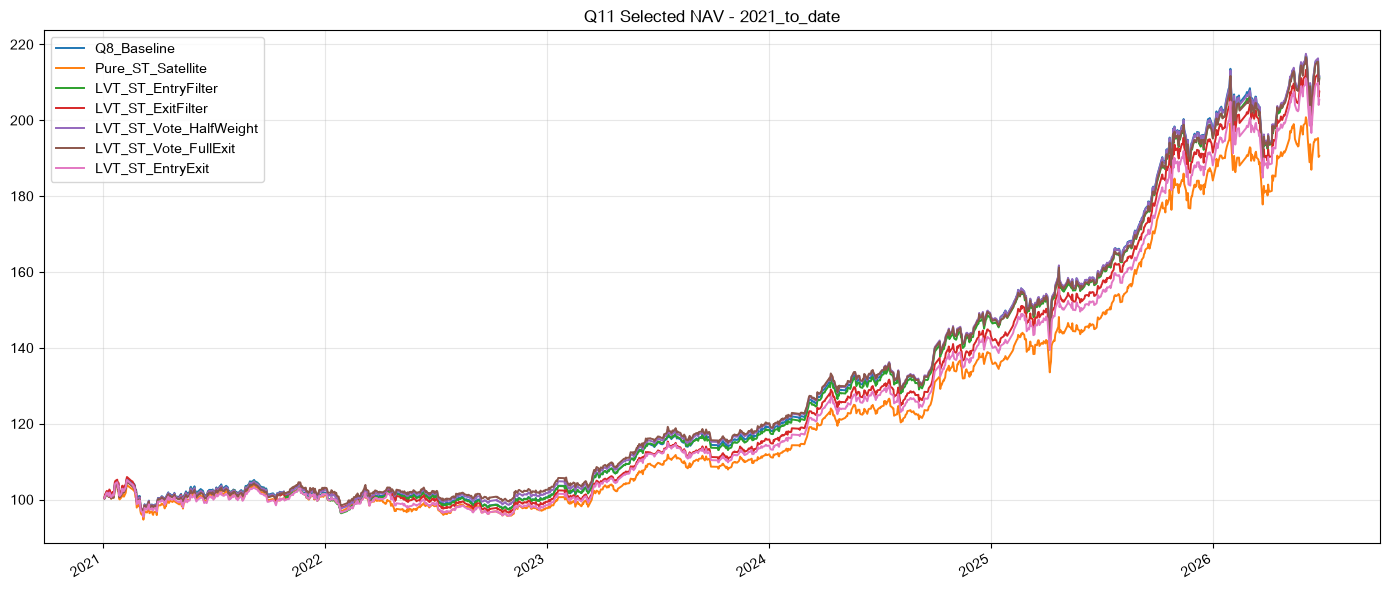

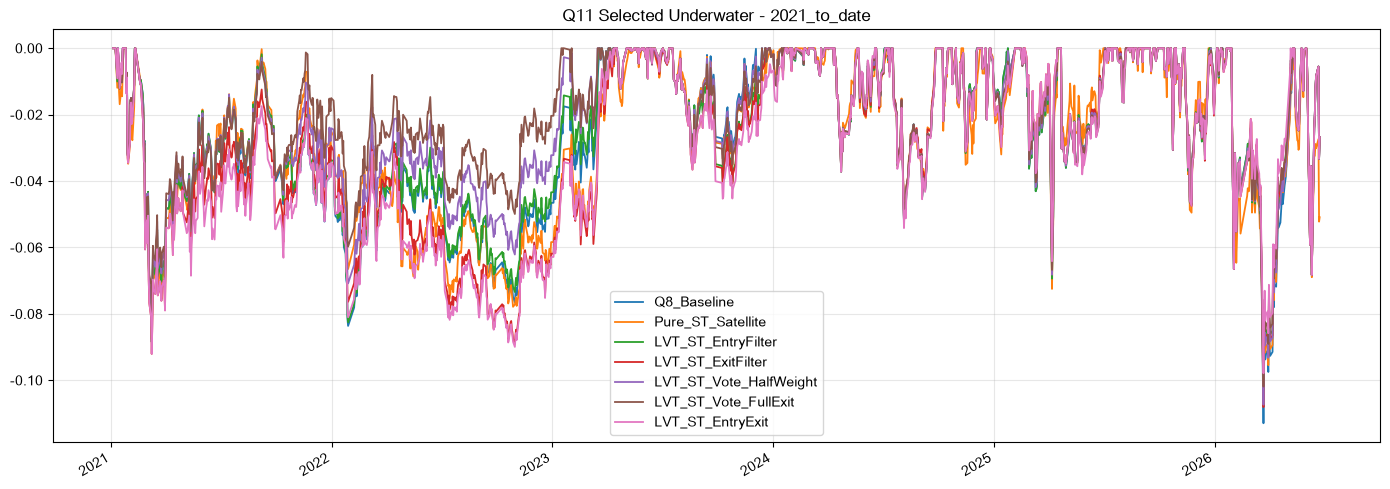

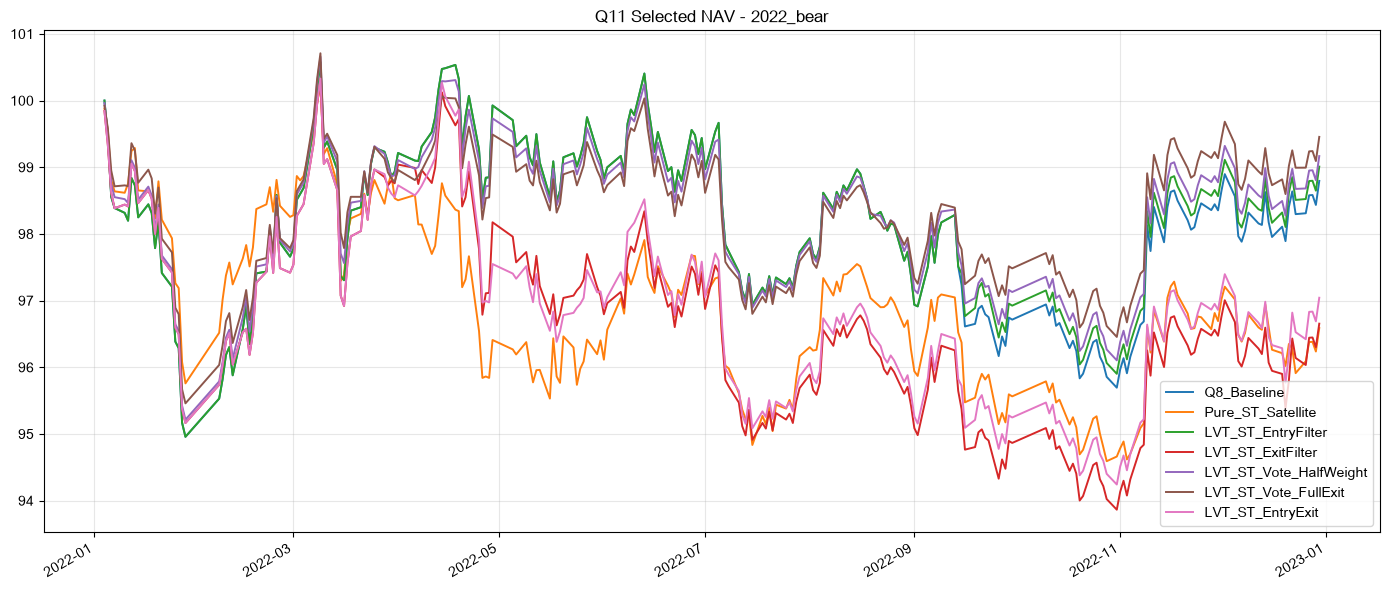

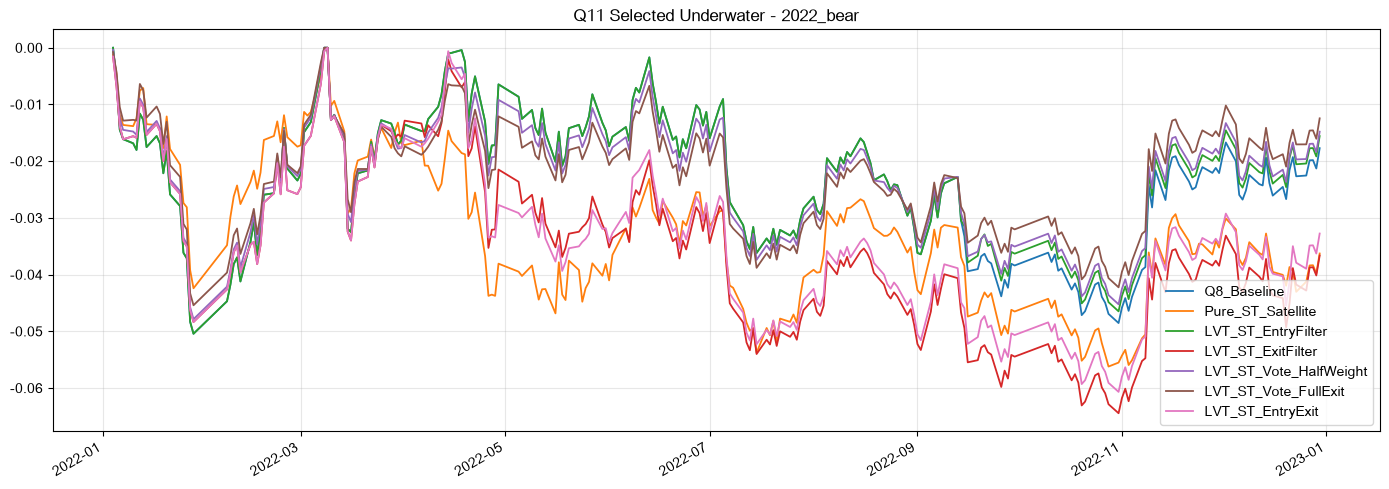

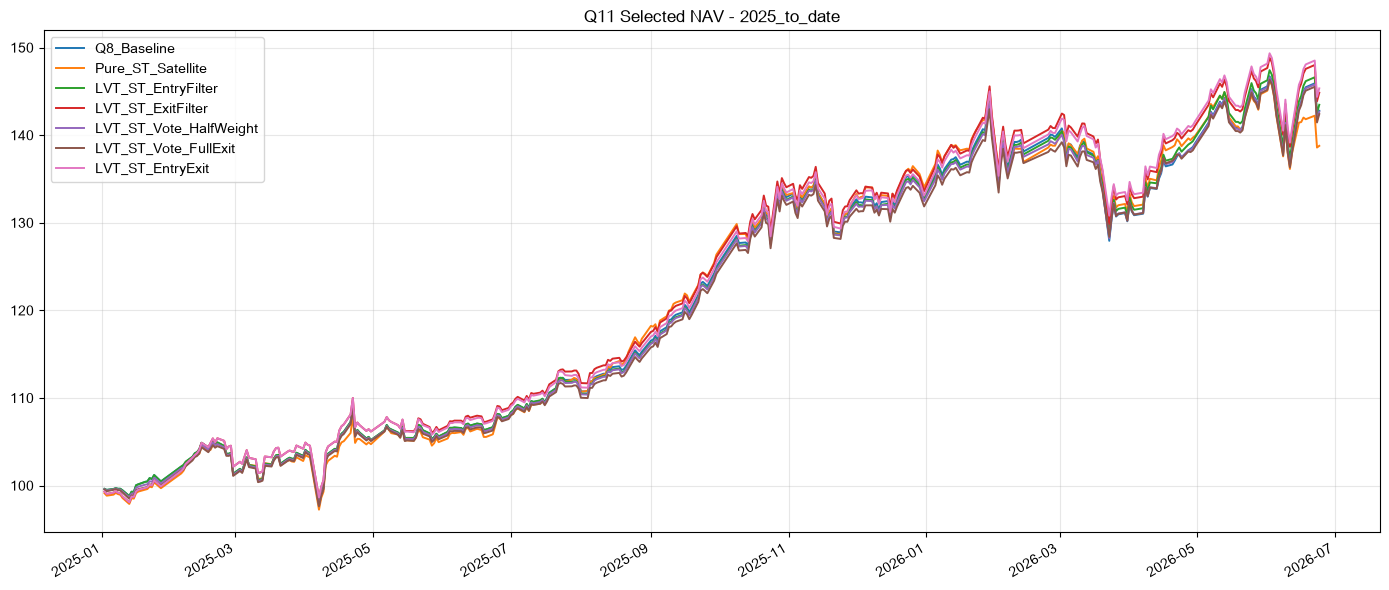

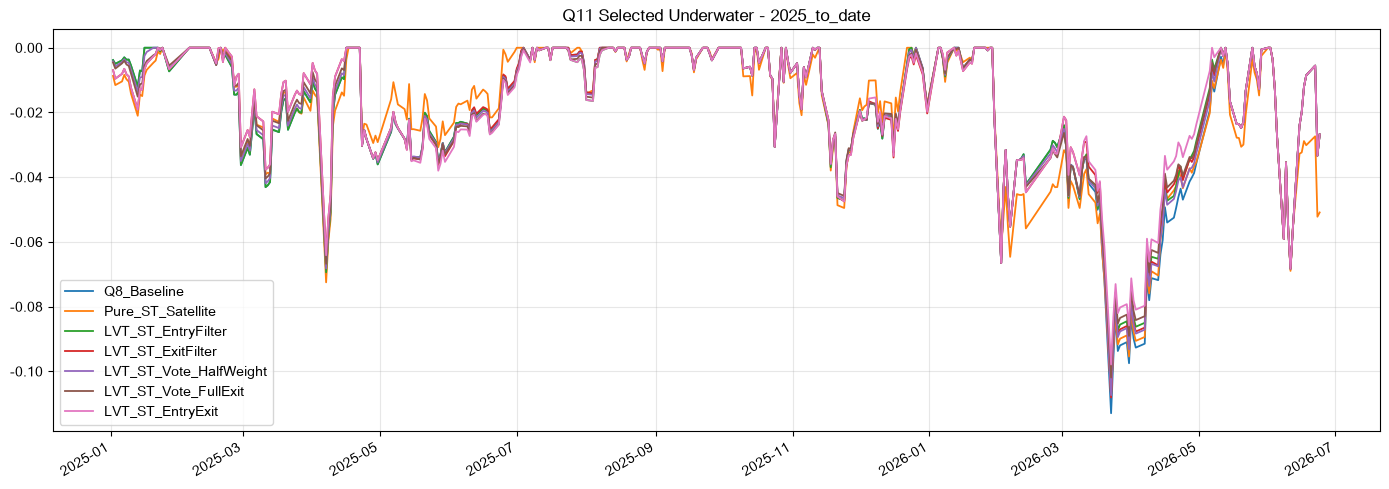

In [8]:
selected_chart = [
    "Q8_Baseline",
    "Pure_ST_Satellite",
    "LVT_ST_EntryFilter",
    "LVT_ST_ExitFilter",
    "LVT_ST_Vote_HalfWeight",
    "LVT_ST_Vote_FullExit",
    "LVT_ST_EntryExit",
]

for window, (start, end) in {k: WINDOWS[k] for k in ["2021_to_date", "2022_bear", "2025_to_date"]}.items():
    navs = {}
    for name in selected_chart:
        r = period_slice(portfolios[name]["returns"], start, end).fillna(0.0)
        navs[name] = nav_from_returns(r)
    nav_df = pd.DataFrame(navs)
    uw_df = nav_df.apply(drawdown_series)
    nav_df.to_csv(OUTPUT_DIR / f"nav_selected_{window}.csv", encoding="utf-8-sig")
    uw_df.to_csv(OUTPUT_DIR / f"underwater_selected_{window}.csv", encoding="utf-8-sig")

    fig, ax = plt.subplots(figsize=(14, 6))
    nav_df.plot(ax=ax, linewidth=1.4)
    ax.set_title(f"Q11 Selected NAV - {window}")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"nav_selected_{window}.png", dpi=160)
    plt.show()

    fig, ax = plt.subplots(figsize=(14, 5))
    uw_df.plot(ax=ax, linewidth=1.3)
    ax.set_title(f"Q11 Selected Underwater - {window}")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"underwater_selected_{window}.png", dpi=160)
    plt.show()


## 交叉验证诊断


In [9]:
def forward_return(sym, loc, horizon):
    start_loc = loc + 1
    end_loc = loc + horizon + 1
    if start_loc >= len(close.index) or end_loc >= len(close.index):
        return np.nan
    start_price = close[sym].iloc[start_loc]
    end_price = close[sym].iloc[end_loc]
    if pd.isna(start_price) or pd.isna(end_price) or start_price <= 0:
        return np.nan
    return end_price / start_price - 1.0


st_default = supertrend_matrix(DEFAULT_ATR, DEFAULT_MULTIPLIER)
diag_rows = []
filtered_rows = []
lvt_overlap_rows = []

for date in sorted(SDATES):
    loc = close.index.get_loc(date)
    lvt = set(low_vol_trend_selection(date))
    st = {sym for sym in EXPANDED_THEME if bool(st_default.at[date, sym])}
    if lvt:
        lvt_overlap_rows.append({
            "date": date,
            "lvt_selected_count": len(lvt),
            "st_long_in_lvt_count": len(lvt & st),
            "st_long_share_in_lvt": len(lvt & st) / len(lvt),
        })
    for sym in EXPANDED_THEME:
        if not enough_history(sym, loc, max(MA_WINDOW, MOM_WINDOW + 1)):
            continue
        lvt_pass = sym in lvt
        st_pass = sym in st
        if lvt_pass and st_pass:
            group = "both_pass"
        elif lvt_pass and not st_pass:
            group = "lvt_only"
        elif (not lvt_pass) and st_pass:
            group = "st_only"
        else:
            group = "neither"
        for h in [10, 20, 40]:
            fr = forward_return(sym, loc, h)
            diag_rows.append({
                "date": date,
                "symbol": sym,
                "name": SYMBOL_NAMES[sym],
                "group": group,
                "horizon": h,
                "forward_return": fr,
            })
            if lvt_pass:
                filtered_rows.append({
                    "date": date,
                    "symbol": sym,
                    "name": SYMBOL_NAMES[sym],
                    "st_state": "st_long" if st_pass else "st_short_filtered",
                    "horizon": h,
                    "forward_return": fr,
                })

overlap = pd.DataFrame(lvt_overlap_rows)
forward_detail = pd.DataFrame(diag_rows).dropna(subset=["forward_return"])
filtered_detail = pd.DataFrame(filtered_rows).dropna(subset=["forward_return"])

overlap_summary = pd.Series({
    "signal_count_with_lvt": len(overlap),
    "asset_weighted_st_long_share_in_lvt": overlap["st_long_in_lvt_count"].sum() / overlap["lvt_selected_count"].sum(),
    "average_signal_st_long_share_in_lvt": overlap["st_long_share_in_lvt"].mean(),
    "median_signal_st_long_share_in_lvt": overlap["st_long_share_in_lvt"].median(),
})

forward_summary = forward_detail.groupby(["horizon", "group"]).agg(
    observations=("forward_return", "count"),
    mean_forward_return=("forward_return", "mean"),
    median_forward_return=("forward_return", "median"),
    win_rate=("forward_return", lambda x: (x > 0).mean()),
    worst=("forward_return", "min"),
    best=("forward_return", "max"),
).reset_index()

filtered_summary = filtered_detail.groupby(["horizon", "st_state"]).agg(
    observations=("forward_return", "count"),
    mean_forward_return=("forward_return", "mean"),
    median_forward_return=("forward_return", "median"),
    win_rate=("forward_return", lambda x: (x > 0).mean()),
    worst=("forward_return", "min"),
    best=("forward_return", "max"),
).reset_index()

overlap.to_csv(OUTPUT_DIR / "lvt_supertrend_overlap_by_signal.csv", index=False, encoding="utf-8-sig")
overlap_summary.to_csv(OUTPUT_DIR / "lvt_supertrend_overlap_summary.csv", encoding="utf-8-sig")
forward_detail.to_csv(OUTPUT_DIR / "forward_return_group_detail.csv", index=False, encoding="utf-8-sig")
forward_summary.to_csv(OUTPUT_DIR / "forward_return_group_summary.csv", index=False, encoding="utf-8-sig")
filtered_detail.to_csv(OUTPUT_DIR / "filtered_asset_forward_return_detail.csv", index=False, encoding="utf-8-sig")
filtered_summary.to_csv(OUTPUT_DIR / "filtered_asset_forward_return_summary.csv", index=False, encoding="utf-8-sig")

print("LVT selected assets with SuperTrend long share")
display(overlap_summary.to_frame("value").round(4))
print("Forward return by four signal groups")
display(forward_summary.round(4))
print("LVT-selected assets: ST-long vs ST-short filtered forward returns")
display(filtered_summary.round(4))


LVT selected assets with SuperTrend long share


,value
signal_count_with_lvt,147.0000
asset_weighted_st_long_share_in_lvt,0.7769
average_signal_st_long_share_in_lvt,0.7698
median_signal_st_long_share_in_lvt,1.0000


Forward return by four signal groups


,horizon,group,observations,mean_forward_return,median_forward_return,win_rate,worst,best
0,10,both_pass,300,0.0125,0.0073,0.5767,-0.1444,0.3399
1,10,lvt_only,87,-0.0017,0.0018,0.5172,-0.1283,0.1461
2,10,neither,581,0.0043,0.0011,0.5060,-0.2238,0.2892
3,10,st_only,478,0.0023,-0.0016,0.4707,-0.6635,0.2845
4,20,both_pass,300,0.0191,0.0097,0.6000,-0.1911,0.2843
5,20,lvt_only,87,-0.0030,0.0035,0.5172,-0.1487,0.1892
6,20,neither,581,0.0113,0.0089,0.5387,-0.2394,0.4852
7,20,st_only,478,0.0063,-0.0028,0.4854,-0.6657,0.4540
8,40,both_pass,291,0.0202,0.0221,0.6082,-0.2041,0.3217
9,40,lvt_only,87,0.0106,0.0057,0.5632,-0.1910,0.1782


LVT-selected assets: ST-long vs ST-short filtered forward returns


,horizon,st_state,observations,mean_forward_return,median_forward_return,win_rate,worst,best
0,10,st_long,300,0.0125,0.0073,0.5767,-0.1444,0.3399
1,10,st_short_filtered,87,-0.0017,0.0018,0.5172,-0.1283,0.1461
2,20,st_long,300,0.0191,0.0097,0.6000,-0.1911,0.2843
3,20,st_short_filtered,87,-0.0030,0.0035,0.5172,-0.1487,0.1892
4,40,st_long,291,0.0202,0.0221,0.6082,-0.2041,0.3217
5,40,st_short_filtered,87,0.0106,0.0057,0.5632,-0.1910,0.1782


In [10]:
baseline_monthly = portfolios["Q8_Baseline"]["returns"].resample("ME").apply(lambda x: (1.0 + x).prod() - 1.0)
exposure_rows = []
upside_rows = []
base_2021 = summary_all[(summary_all["window"] == "2021_to_date") & (summary_all["strategy"] == "Q8_Baseline")].iloc[0]

for name, port in portfolios.items():
    row = summary_all[(summary_all["window"] == "2021_to_date") & (summary_all["strategy"] == name)].iloc[0].to_dict()
    row["delta_年化收益_vs_Q8"] = row["年化收益"] - base_2021["年化收益"]
    row["delta_最大回撤_vs_Q8"] = row["最大回撤"] - base_2021["最大回撤"]
    row["delta_平均风险资产暴露_vs_Q8"] = row["平均风险资产暴露"] - base_2021["平均风险资产暴露"]
    row["return_per_avg_exposure"] = row["年化收益"] / row["平均风险资产暴露"] if row["平均风险资产暴露"] > 0 else np.nan
    row["drawdown_per_avg_exposure"] = row["最大回撤"] / row["平均风险资产暴露"] if row["平均风险资产暴露"] > 0 else np.nan
    exposure_rows.append(row)

    monthly = port["returns"].resample("ME").apply(lambda x: (1.0 + x).prod() - 1.0)
    joined = pd.concat([baseline_monthly.rename("baseline"), monthly.rename("variant")], axis=1).dropna()
    up_months = joined[joined["baseline"] > 0]
    upside_rows.append({
        "strategy": name,
        "baseline_positive_months": len(up_months),
        "underperform_positive_months": int((up_months["variant"] < up_months["baseline"]).sum()),
        "underperform_positive_month_rate": (up_months["variant"] < up_months["baseline"]).mean() if len(up_months) else np.nan,
        "avg_monthly_upside_miss_when_baseline_positive": (up_months["variant"] - up_months["baseline"]).mean() if len(up_months) else np.nan,
        "worst_monthly_upside_miss_when_baseline_positive": (up_months["variant"] - up_months["baseline"]).min() if len(up_months) else np.nan,
    })

exposure_diagnostics = pd.DataFrame(exposure_rows)
upside_miss = pd.DataFrame(upside_rows)
exposure_diagnostics.to_csv(OUTPUT_DIR / "exposure_diagnostics_vs_q8.csv", index=False, encoding="utf-8-sig")
upside_miss.to_csv(OUTPUT_DIR / "upside_miss_diagnostics_vs_q8.csv", index=False, encoding="utf-8-sig")

display(exposure_diagnostics[["strategy", "年化收益", "最大回撤", "平均风险资产暴露", "平均现金/Def200权重", "平均卫星现金", "delta_年化收益_vs_Q8", "delta_最大回撤_vs_Q8", "delta_平均风险资产暴露_vs_Q8", "return_per_avg_exposure"]].round(4))
display(upside_miss.round(4))


,strategy,年化收益,最大回撤,平均风险资产暴露,平均现金/Def200权重,平均卫星现金,delta_年化收益_vs_Q8,delta_最大回撤_vs_Q8,delta_平均风险资产暴露_vs_Q8,return_per_avg_exposure
0,Q8_Baseline,0.1532,-0.1129,0.8379,0.1621,0.0017,0.0000,0.0000,0.0000,0.1828
1,Pure_LVT_Satellite,0.1532,-0.1129,0.8379,0.1621,0.0017,0.0000,0.0000,0.0000,0.1828
2,Pure_ST_Satellite,0.1306,-0.1073,0.8394,0.1606,0.0012,-0.0226,0.0056,0.0015,0.1556
3,LVT_ST_EntryFilter,0.1529,-0.1031,0.8379,0.1621,0.0017,-0.0003,0.0099,0.0000,0.1824
4,LVT_ST_ExitFilter,0.1491,-0.1081,0.8312,0.1688,0.0077,-0.0041,0.0049,-0.0067,0.1794
5,LVT_ST_Vote_HalfWeight,0.1535,-0.1074,0.8181,0.1819,0.0221,0.0003,0.0056,-0.0198,0.1876
6,LVT_ST_Vote_FullExit,0.1526,-0.1019,0.7977,0.2023,0.0426,-0.0006,0.0110,-0.0402,0.1912
7,LVT_ST_EntryExit,0.1468,-0.0979,0.8290,0.1710,0.0103,-0.0063,0.0151,-0.0090,0.1771


,strategy,baseline_positive_months,underperform_positive_months,underperform_positive_month_rate,avg_monthly_upside_miss_when_baseline_positive,worst_monthly_upside_miss_when_baseline_positive
0,Q8_Baseline,50,0,0.00,0.0000,0.0000
1,Pure_LVT_Satellite,50,0,0.00,0.0000,0.0000
2,Pure_ST_Satellite,50,33,0.66,-0.0023,-0.0316
3,LVT_ST_EntryFilter,50,8,0.16,-0.0002,-0.0043
4,LVT_ST_ExitFilter,50,20,0.40,0.0001,-0.0160
5,LVT_ST_Vote_HalfWeight,50,28,0.56,-0.0005,-0.0038
6,LVT_ST_Vote_FullExit,50,29,0.58,-0.0010,-0.0077
7,LVT_ST_EntryExit,50,26,0.52,-0.0006,-0.0202


## SuperTrend 参数敏感性


,strategy,atr,multiplier,is_default,累计收益,年化收益,最大回撤,Sharpe,Calmar,Sortino,最长水下天数,超过-10%天数,平均现金/Def200权重,年化换手,年化成本拖累,Calmar_rank_in_strategy,Sharpe_rank_in_strategy
9,LVT_ST_EntryExit,7,2.0,False,1.1937,0.1613,-0.0979,1.4945,1.6478,1.4326,184,0,0.1806,6.7338,0.0195,1.0,1.0
12,LVT_ST_EntryExit,10,2.0,False,1.1455,0.1564,-0.0979,1.4471,1.5977,1.3812,466,0,0.1798,6.7819,0.0196,2.0,2.0
13,LVT_ST_EntryExit,10,3.0,True,1.0542,0.1468,-0.0979,1.3594,1.5003,1.2934,524,0,0.1710,6.7380,0.0196,3.0,7.0
14,LVT_ST_EntryExit,10,4.0,False,1.0888,0.1505,-0.1027,1.3982,1.4647,1.3309,535,1,0.1702,6.2912,0.0182,4.0,4.0
16,LVT_ST_EntryExit,14,3.0,False,1.1396,0.1558,-0.1081,1.4227,1.4413,1.3513,506,1,0.1730,6.8281,0.0199,5.0,3.0
11,LVT_ST_EntryExit,7,4.0,False,1.0570,0.1471,-0.1030,1.3654,1.4291,1.2967,537,7,0.1704,6.2571,0.0181,6.0,6.0
15,LVT_ST_EntryExit,14,2.0,False,1.0626,0.1477,-0.1084,1.3682,1.3632,1.3064,467,1,0.1848,6.6848,0.0193,7.0,5.0
17,LVT_ST_EntryExit,14,4.0,False,1.0249,0.1437,-0.1055,1.3337,1.3619,1.2693,545,13,0.1686,6.4452,0.0188,8.0,8.0
10,LVT_ST_EntryExit,7,3.0,False,1.0267,0.1439,-0.1081,1.3314,1.3314,1.2644,540,9,0.1734,6.6368,0.0193,9.0,9.0
27,LVT_ST_Vote_FullExit,7,2.0,False,1.1114,0.1529,-0.1019,1.4898,1.5001,1.4173,239,1,0.2213,5.8099,0.0167,1.0,1.0


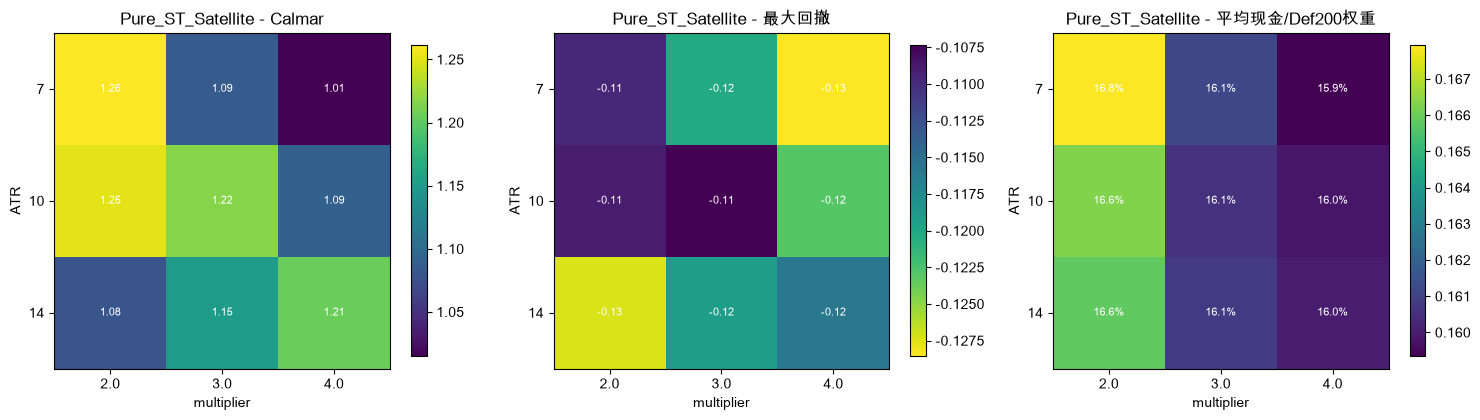

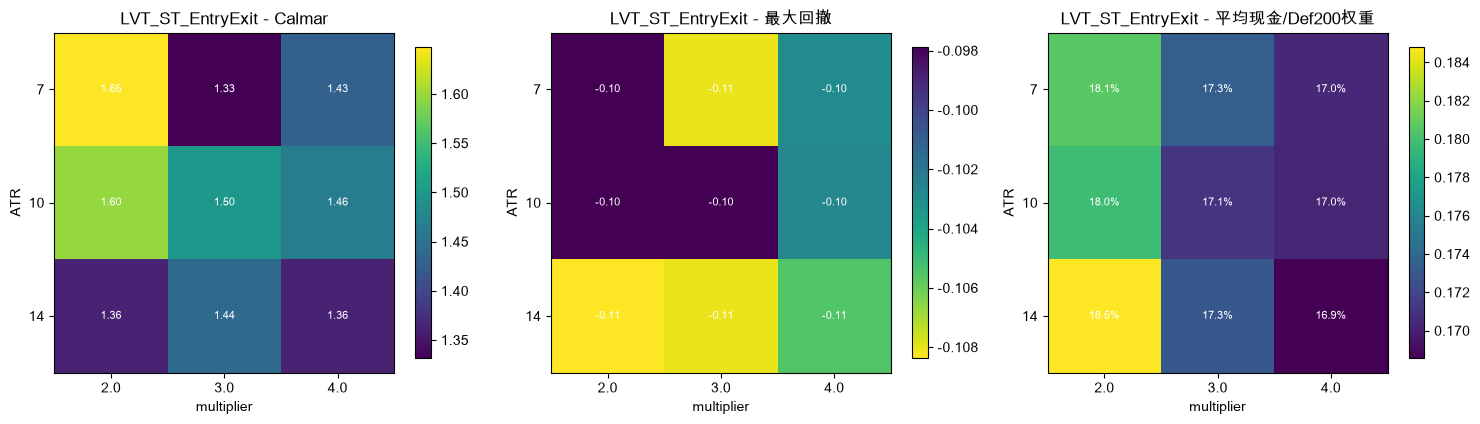

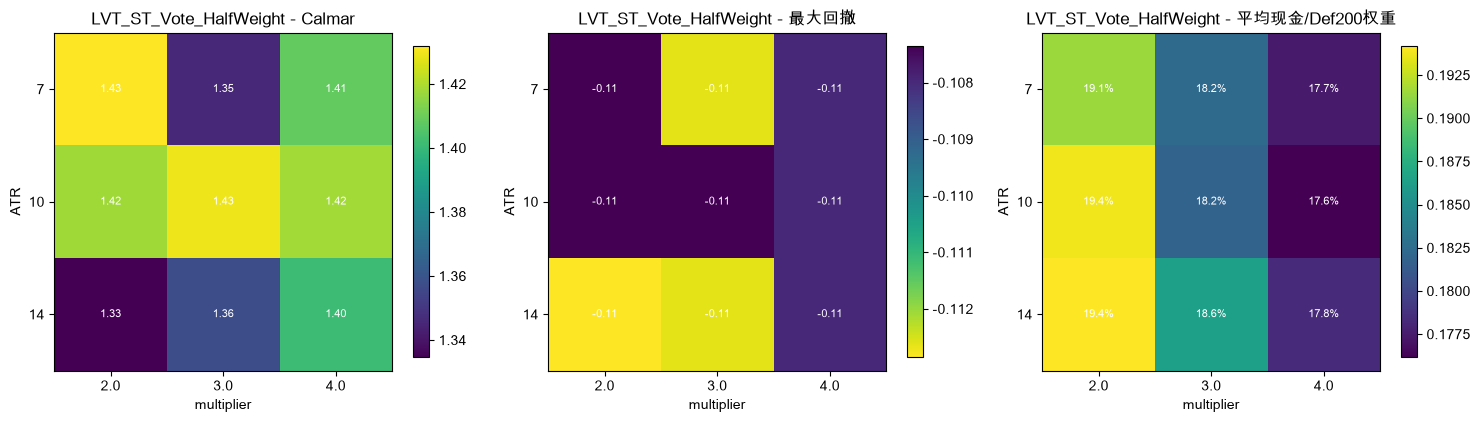

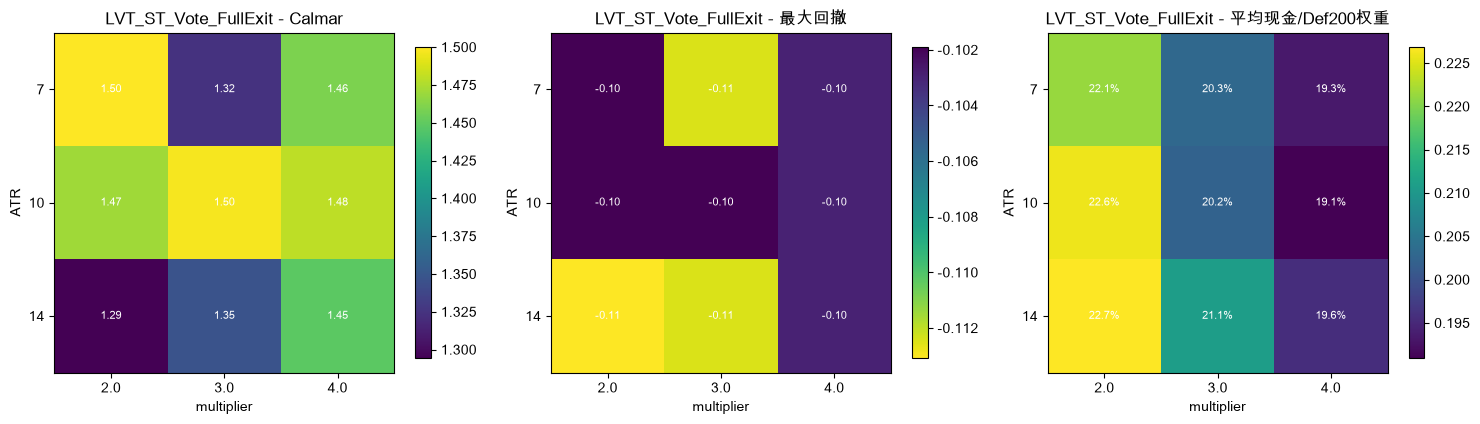

In [11]:
sensitivity_kinds = ["Pure_ST_Satellite", "LVT_ST_EntryExit", "LVT_ST_Vote_HalfWeight", "LVT_ST_Vote_FullExit"]
sensitivity_rows = []

for kind, atr, mult in product(sensitivity_kinds, [7, 10, 14], [2.0, 3.0, 4.0]):
    sat = build_satellite_weights(kind, atr=atr, multiplier=mult)
    target = combine_core_satellite(core_def200, sat)
    port = backtest(f"{kind}_ATR{atr}_M{mult:g}", target, sat)
    row = metrics_row(kind, port, "2021-01-01", None)
    row["strategy"] = kind
    row["atr"] = atr
    row["multiplier"] = mult
    row["is_default"] = atr == DEFAULT_ATR and float(mult) == DEFAULT_MULTIPLIER
    row["delta_年化收益_vs_Q8"] = row["年化收益"] - base_2021["年化收益"]
    row["delta_Calmar_vs_Q8"] = row["Calmar"] - base_2021["Calmar"]
    row["delta_最大回撤_vs_Q8"] = row["最大回撤"] - base_2021["最大回撤"]
    row["delta_平均现金_vs_Q8"] = row["平均现金/Def200权重"] - base_2021["平均现金/Def200权重"]
    sensitivity_rows.append(row)

parameter_sensitivity = pd.DataFrame(sensitivity_rows)
parameter_sensitivity["Calmar_rank_in_strategy"] = parameter_sensitivity.groupby("strategy")["Calmar"].rank(ascending=False, method="min")
parameter_sensitivity["Sharpe_rank_in_strategy"] = parameter_sensitivity.groupby("strategy")["Sharpe"].rank(ascending=False, method="min")
parameter_sensitivity.to_csv(OUTPUT_DIR / "supertrend_parameter_sensitivity.csv", index=False, encoding="utf-8-sig")

display(parameter_sensitivity[[
    "strategy", "atr", "multiplier", "is_default", "累计收益", "年化收益", "最大回撤", "Sharpe", "Calmar", "Sortino",
    "最长水下天数", "超过-10%天数", "平均现金/Def200权重", "年化换手", "年化成本拖累", "Calmar_rank_in_strategy", "Sharpe_rank_in_strategy"
]].sort_values(["strategy", "Calmar_rank_in_strategy"]).round(4))

for strategy in sensitivity_kinds:
    subset = parameter_sensitivity[parameter_sensitivity["strategy"] == strategy]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    for metric, ax in [("Calmar", axes[0]), ("最大回撤", axes[1]), ("平均现金/Def200权重", axes[2])]:
        pivot = subset.pivot(index="atr", columns="multiplier", values=metric)
        cmap = "viridis_r" if metric == "最大回撤" else "viridis"
        im = ax.imshow(pivot.values, cmap=cmap)
        ax.set_title(f"{strategy} - {metric}")
        ax.set_xticks(range(len(pivot.columns)), labels=[str(c) for c in pivot.columns])
        ax.set_yticks(range(len(pivot.index)), labels=[str(i) for i in pivot.index])
        ax.set_xlabel("multiplier")
        ax.set_ylabel("ATR")
        for i in range(len(pivot.index)):
            for j in range(len(pivot.columns)):
                val = pivot.values[i, j]
                label = f"{val:.2f}" if "权重" not in metric else f"{val:.1%}"
                ax.text(j, i, label, ha="center", va="center", color="white", fontsize=8)
        fig.colorbar(im, ax=ax, shrink=0.75)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"parameter_heatmap_{strategy}.png", dpi=160)
    plt.show()


## 当前信号与结论文件


In [12]:
latest_date = close.index[-1]
latest_signal_date = max(d for d in SDATES if d <= latest_date)
latest_lvt = low_vol_trend_selection(latest_signal_date)
latest_st = supertrend_matrix(DEFAULT_ATR, DEFAULT_MULTIPLIER).loc[latest_signal_date]

latest_signal_rows = []
for sym in EXPANDED_THEME:
    latest_signal_rows.append({
        "signal_date": latest_signal_date.date(),
        "data_date": latest_date.date(),
        "symbol": sym,
        "name": SYMBOL_NAMES[sym],
        "lvt_selected": sym in latest_lvt,
        "supertrend_long": bool(latest_st[sym]),
        "close": close.at[latest_signal_date, sym],
    })
latest_signal_summary = pd.DataFrame(latest_signal_rows)
latest_signal_summary.to_csv(OUTPUT_DIR / "latest_signal_summary.csv", index=False, encoding="utf-8-sig")
display(latest_signal_summary)

research_summary = pd.Series({
    "data_start": str(close.index[0].date()),
    "data_end": str(close.index[-1].date()),
    "latest_signal_date": str(latest_signal_date.date()),
    "baseline": "Q8_Baseline / Core80 Expanded LVT20 Def200 Cash / BIMONTHLY / next_close / base20_plus_asset",
    "default_supertrend": f"ATR{DEFAULT_ATR}_multiplier{DEFAULT_MULTIPLIER:g}",
    "lvt_selected_st_long_share_asset_weighted": float(overlap_summary["asset_weighted_st_long_share_in_lvt"]),
    "lvt_selected_st_long_share_average_signal": float(overlap_summary["average_signal_st_long_share_in_lvt"]),
})
research_summary.to_csv(OUTPUT_DIR / "research_summary.csv", encoding="utf-8-sig")
research_summary


,signal_date,data_date,symbol,name,lvt_selected,supertrend_long,close
0,2026-06-10,2026-06-24,513100.SS,纳指100ETF,True,True,2.143
1,2026-06-10,2026-06-24,512400.SS,有色金属ETF,False,False,1.843
2,2026-06-10,2026-06-24,159995.SZ,芯片ETF,True,True,2.387
3,2026-06-10,2026-06-24,515880.SS,通信ETF,True,True,1.630
4,2026-06-10,2026-06-24,518880.SS,黄金ETF,False,False,8.736
5,2026-06-10,2026-06-24,510880.SS,红利ETF,False,True,3.261
6,2026-06-10,2026-06-24,159930.SZ,能源ETF,False,True,1.704
7,2026-06-10,2026-06-24,512880.SS,证券ETF,False,False,1.018
8,2026-06-10,2026-06-24,513180.SS,恒生科技ETF,False,False,0.599
9,2026-06-10,2026-06-24,512170.SS,医疗ETF,False,False,0.291


data_start                                                                          2020-01-02
data_end                                                                            2026-06-24
latest_signal_date                                                                  2026-06-10
baseline                                     Q8_Baseline / Core80 Expanded LVT20 Def200 Cas...
default_supertrend                                                           ATR10_multiplier3
lvt_selected_st_long_share_asset_weighted                                             0.776923
lvt_selected_st_long_share_average_signal                                             0.769841
dtype: object

In [13]:
def pct(x):
    if pd.isna(x):
        return "n/a"
    return f"{x:.2%}"


def num(x):
    if pd.isna(x):
        return "n/a"
    return f"{x:.2f}"


def md_table(df, cols, max_rows=None):
    d = df[cols].copy()
    if max_rows is not None:
        d = d.head(max_rows)
    return d.to_markdown(index=False)


main_2021 = summary_all[summary_all["window"] == "2021_to_date"].copy()
baseline = main_2021[main_2021["strategy"] == "Q8_Baseline"].iloc[0]
historical_best = main_2021.sort_values("累计收益", ascending=False).iloc[0]
risk_best = main_2021.sort_values("Sharpe", ascending=False).iloc[0]

balanced_score = main_2021.copy()
for col, ascending in [("Calmar", False), ("Sharpe", False), ("最大回撤", False), ("最长水下天数", True), ("平均现金/Def200权重", True)]:
    balanced_score[f"rank_{col}"] = balanced_score[col].rank(ascending=ascending, method="min")
balanced_score["balanced_rank_sum"] = balanced_score[[c for c in balanced_score.columns if c.startswith("rank_")]].sum(axis=1)
balanced_best = balanced_score.sort_values("balanced_rank_sum").iloc[0]

default_sens = parameter_sensitivity[parameter_sensitivity["is_default"]].copy()
param_shape = parameter_sensitivity.groupby("strategy").agg(
    cases=("Calmar", "count"),
    calmar_min=("Calmar", "min"),
    calmar_median=("Calmar", "median"),
    calmar_max=("Calmar", "max"),
    maxdd_min=("最大回撤", "min"),
    maxdd_max=("最大回撤", "max"),
    avg_cash_median=("平均现金/Def200权重", "median"),
).reset_index()

filtered_pivot = filtered_summary.pivot(index="horizon", columns="st_state", values="mean_forward_return")
filter_read = []
for h in [10, 20, 40]:
    if h in filtered_pivot.index and "st_long" in filtered_pivot.columns and "st_short_filtered" in filtered_pivot.columns:
        filter_read.append(f"{h}D: ST-long {pct(filtered_pivot.loc[h, 'st_long'])}, ST-short {pct(filtered_pivot.loc[h, 'st_short_filtered'])}")

four_group = forward_summary.pivot(index="horizon", columns="group", values="mean_forward_return")
group_read = []
for h in [10, 20, 40]:
    pieces = []
    for g in ["both_pass", "lvt_only", "st_only", "neither"]:
        if h in four_group.index and g in four_group.columns:
            pieces.append(f"{g} {pct(four_group.loc[h, g])}")
    group_read.append(f"{h}D: " + ", ".join(pieces))

paper_candidate = "LVT_ST_Vote_HalfWeight"
if balanced_best["strategy"] in ["Q8_Baseline", "Pure_LVT_Satellite"]:
    paper_candidate = "Q8_Baseline"
elif balanced_best["strategy"] in STRATEGY_DEFINITIONS:
    paper_candidate = balanced_best["strategy"]

note = f"""# Q11 SuperTrend 与低波趋势 LVT 交叉验证 Review

Date: {pd.Timestamp.today().date()}

## Purpose

Q11 tests whether SuperTrend adds independent structure to the Q8 Theme Alpha baseline, or whether it mostly duplicates LowVolTrend.

The baseline is unchanged:

- Core80 / Expanded LVT20 / Def200 Cash
- fixed twice-monthly calendar signals
- close-signal-next-day-trade
- 20 bps base cost plus asset friction
- 2% minimum rebalance threshold and 15% max single-ETF trade cap

Default SuperTrend uses ATR {DEFAULT_ATR} / multiplier {DEFAULT_MULTIPLIER:g}, with sensitivity over ATR 7/10/14 and multiplier 2/3/4.

## Strategy Definitions

| Strategy | Definition |
|---|---|
"""
for k, v in STRATEGY_DEFINITIONS.items():
    note += f"| `{k}` | {v} |\n"

note += f"""

Important note: `Q8_Baseline` and `Pure_LVT_Satellite` are intentionally identical in this notebook. The first name anchors comparison to Q8; the second names the satellite engine being cross-validated.

## Main 2021-To-Date Results

{md_table(main_2021.sort_values('Calmar', ascending=False), ['strategy', '累计收益', '年化收益', '年化波动', '最大回撤', 'Sharpe', 'Calmar', 'Sortino', '最长水下天数', '超过-10%天数', '平均现金/Def200权重', '平均卫星现金'])}

## Window Results

{md_table(summary_all[summary_all['strategy'].isin(['Q8_Baseline', 'Pure_ST_Satellite', 'LVT_ST_EntryFilter', 'LVT_ST_ExitFilter', 'LVT_ST_Vote_HalfWeight', 'LVT_ST_Vote_FullExit', 'LVT_ST_EntryExit'])].sort_values(['window', 'strategy']), ['window', 'strategy', '累计收益', '最大回撤', 'Sharpe', 'Calmar', '最长水下天数', '超过-10%天数', '年化换手', '年化成本拖累', '平均现金/Def200权重'])}

## Cross-Validation Diagnostics

- LVT-selected assets were also SuperTrend-long {pct(overlap_summary['asset_weighted_st_long_share_in_lvt'])} of the time on an asset-count basis; the average signal-date overlap was {pct(overlap_summary['average_signal_st_long_share_in_lvt'])}.
- Forward returns for LVT-selected names split by ST state: {'; '.join(filter_read)}.
- Four-way forward-return groups: {'; '.join(group_read)}.
- Exposure diagnosis is in `exposure_diagnostics_vs_q8.csv`; upside-miss diagnosis is in `upside_miss_diagnostics_vs_q8.csv`.

## Parameter Sensitivity

{md_table(param_shape, ['strategy', 'cases', 'calmar_min', 'calmar_median', 'calmar_max', 'maxdd_min', 'maxdd_max', 'avg_cash_median'])}

Default-parameter ranks:

{md_table(default_sens.sort_values('strategy'), ['strategy', 'atr', 'multiplier', 'Calmar', 'Sharpe', 'Calmar_rank_in_strategy', 'Sharpe_rank_in_strategy', '平均现金/Def200权重'])}

## Interpretation

- Historical best: `{historical_best['strategy']}` with 2021-to-date cumulative return {pct(historical_best['累计收益'])}.
- Risk-adjusted best: `{risk_best['strategy']}` by Sharpe ({num(risk_best['Sharpe'])}); Calmar should be checked alongside it because several variants mostly improve by reducing exposure.
- Most structurally balanced: `{balanced_best['strategy']}` by the simple rank blend of Calmar, Sharpe, drawdown, longest underwater, and cash exposure.
- SuperTrend enhancement read: the overlap rate is material but not complete. This means SuperTrend is not identical to LVT, but a large part of its apparent risk reduction must be checked against lower exposure and higher cash.
- Best role: compare `LVT_ST_Vote_HalfWeight` and `LVT_ST_Vote_FullExit` before adopting a hard entry/exit filter. Hard filters are easier to overfit and can convert a ranking signal into a binary timing signal.
- Complement or duplicate: partly complementary, but not a clean independent alpha. The strongest evidence for complementarity is whether ST-short LVT names have weaker 10/20/40D forward returns; the strongest evidence for duplication is the high overlap among selected names.
- Paper-tracking candidate: `{paper_candidate}` if the goal is to study SuperTrend interaction; otherwise keep `Q8_Baseline` as the operating benchmark and track the hybrid only side-by-side.
- Likely sample luck: parameter-specific wins, especially any setting that improves return while also raising cash or reducing exposure. Treat those as de-risking effects until forward diagnostics and paper tracking confirm otherwise.
- Market environments that can hurt the hybrid: fast V-shaped rebounds after ST exits, choppy trend reversals around the SuperTrend line, theme leadership rotations where LVT finds a good asset before ST confirms, and broad ETF gap-down events between signal dates.
- Paper tracking decision: worth side-by-side paper tracking, not worth replacing Q8 baseline yet. The right next phase is to track Q8 baseline, half-weight vote, full-exit vote, and entry+exit upper reference under the same live signal ledger.

## Files

- Notebook: `q11-supertrend-lvt-cross-validation-practice.ipynb`
- Outputs: `outputs/q11-supertrend-lvt-cross-validation/`
- Main summary: `summary_all_windows.csv`
- Parameter sensitivity: `supertrend_parameter_sensitivity.csv`
- Forward diagnostics: `forward_return_group_summary.csv`, `filtered_asset_forward_return_summary.csv`
- Latest signal: `latest_signal_summary.csv`, `latest_target_weights.csv`
"""

Path("docs/notes").mkdir(parents=True, exist_ok=True)
review_path = Path("docs/notes/q11-supertrend-lvt-cross-validation-review.md")
review_path.write_text(note, encoding="utf-8")
print(review_path)


docs/notes/q11-supertrend-lvt-cross-validation-review.md
